### The Newsvendor Problem
Previously, planning production around the average demand cost the bakery 20% of its potential profit. So how much should it actually produce?

Consider the same bakery, which serves an average of 100 customers per day, although actual demand fluctuates. It now sells cakes that cost $6 to make and cookies that costs $2. Both sell for $10.

In [1]:
library(ggplot2)

In [2]:
avg_demand <- 100   # average customers per day (same for both products)
demand_sd <- 20     # how much demand swings day to day
products <- data.frame(name = c("Cakes", "Cookies"),
                       price = c(10, 10),   # selling price per item
                       cost = c(6, 2))      # cost to make one item (leftovers are thrown away)
currency <- "$"
set.seed(2026)

The accompanying chart simulates 20,000 days and compares average daily profit across production  quantities ranging from 60 to 150 units.

In [3]:
# Simulate with varying quantities
quantities <- 60:150   # production levels to test
n_days <- 20000    # simulated days per quantity

demand <- pmax(0, round(rnorm(n_days, avg_demand, demand_sd)))

# Average daily profit for making q items
avg_profit <- function(q, price, cost) {
  mean(price * pmin(demand, q) - cost * q)
}

results <- do.call(rbind, lapply(seq_len(nrow(products)), function(i) {
  data.frame(product = products$name[i],
             quantity = quantities,
             profit = sapply(quantities, avg_profit,
                             price = products$price[i], 
                             cost = products$cost[i]))
}))

In [4]:
# Find the optimal quantity for each product
best <- do.call(rbind, lapply(split(results, results$product), function(d) d[which.max(d$profit), ]))
at_avg <- results[results$quantity == avg_demand, ]

products$sell_chance_needed <- products$cost / products$price
products$formula_qty <- round(qnorm(1 - products$sell_chance_needed,
                                    avg_demand, demand_sd))

for (i in seq_len(nrow(products))) {
  nm <- products$name[i]
  b <- best[best$product == nm, ]
  a <- at_avg[at_avg$product == nm, ]
  cat(sprintf("%-8s best = %d (formula %d) | profit %s%.0f vs %s%.0f if making the average (%+.0f%%)\n",
              nm, b$quantity, products$formula_qty[i],
              currency, b$profit, currency, a$profit,
              (b$profit / a$profit - 1) * 100))
}

Cakes    best = 95 (formula 95) | profit $323 vs $321 if making the average (+1%)
Cookies  best = 117 (formula 117) | profit $745 vs $721 if making the average (+3%)


The results reveal two different optimal production levels.

Why the difference? It comes down to profit margins.

For high-margin products, the cost of missing a potential sale outweighs the risk of having leftover inventory. For low-margin products, the cost of unsold inventory is relatively more significant than the profit lost from a missed sale.

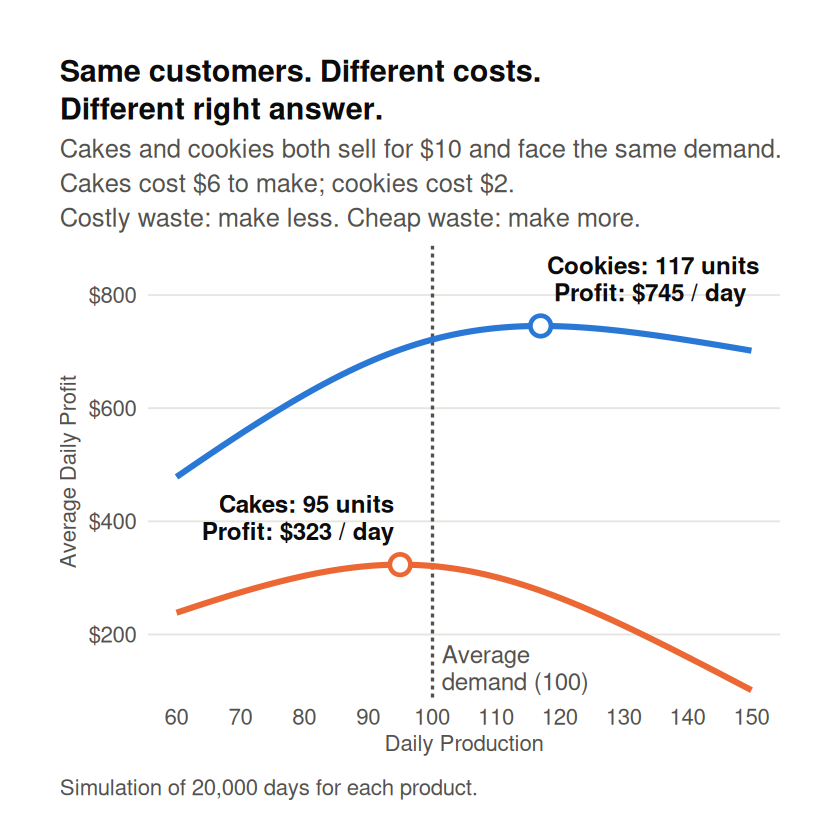

In [9]:
# Chart
blue <- "#2a78d6"
orange <- "#eb6834"
ink <- "#0b0b0b"
ink2 <- "#52514e"
cols <- setNames(c(orange, blue), products$name)

best$label <- sprintf("%s: %d units\n Profit: %s%.0f / day", best$product, best$quantity,
                      currency, best$profit)
y_top <- max(results$profit)
y_lo <- min(results$profit[results$quantity >= 70])

ggplot(results, aes(quantity, profit, colour = product)) +
geom_vline(xintercept = avg_demand, linetype = "dashed",
           colour = ink2, linewidth = 0.7) +
annotate("text", x = avg_demand + 1.5, y = y_lo, hjust = 0, vjust = 0,
         label = sprintf("Average\ndemand (%d)", avg_demand),
         colour = ink2, size = 5, lineheight = 0.95) +
geom_line(linewidth = 1.3) +
geom_point(data = best, size = 4.5, stroke = 1.5, shape = 21, fill = "white") +
geom_text(data = best,
          aes(x = quantity + ifelse(quantity < avg_demand, -1, 1),
              label = label, hjust = ifelse(quantity < avg_demand, 1, 0)),
          vjust = -0.55, size = 5, fontface = "bold", lineheight = 0.95,
          colour = ink) +
scale_colour_manual(values = cols, guide = "none") +
scale_x_continuous(breaks = seq(60, 150, by = 10)) +
scale_y_continuous(labels = function(y) paste0(currency, y),
                   expand = expansion(mult = c(0.02, 0.22))) +
coord_cartesian(ylim = c(y_lo, NA)) +
labs(title = "Same customers. Different costs.\nDifferent right answer.",
     subtitle = paste0("Cakes and cookies both sell for $10 and face the same demand.\n",
                       "Cakes cost $6 to make; cookies cost $2.\n",
                       "Costly waste: make less. Cheap waste: make more."),
     x = "Daily Production",
     y = "Average Daily Profit",
     caption = sprintf("Simulation of %s days for each product.",
                      format(n_days, big.mark = ","))) +
theme_minimal(base_size = 15) +
theme(plot.background = element_rect(fill = "white", colour = NA),
      plot.title = element_text(face = "bold", size = 18, colour = ink,
                                lineheight = 1.05),
      plot.subtitle = element_text(size = 15, colour = ink2, lineheight = 1.15),
      plot.caption = element_text(size = 13, colour = ink2, hjust = 0,
                                      margin = margin(t = 14)),
      plot.title.position = "plot",
      plot.caption.position = "plot",
      axis.title = element_text(colour = ink2, size = 13),
      axis.text = element_text(colour = ink2, size = 13),
      panel.grid.minor = element_blank(),
      panel.grid.major.x = element_blank(),
      panel.grid.major.y = element_line(colour = "#e6e5e0", linewidth = 0.4),
      plot.margin = margin(36, 36, 24, 36))